# CSI change detection and unsupervised state discovery

Implements dataset handling, change models, unsupervised comparisons, and
leakage checks. Supervised models live in **csi_classification.ipynb**.
Select `E:\Espressif\tools\python\v6.1\venv\Scripts\python.exe` in VS Code.
Install `requirements-modeling.txt` using that interpreter if needed.

**All estimator definitions, preprocessing, candidate arrays, and thresholds are
visible below.** Add a named pipeline to the relevant list to compare it on the
same split. Evaluation helpers are editable in `csi_models.py`.

With the supplied single unlabeled capture, clustering can run as a marked
within-session exploration. Reference change detection and occupancy metrics
are skipped until genuine annotations/reference sessions exist.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA

relative = Path('drafts/modeling_and_analysis')
search = [candidate for parent in (Path.cwd(), *Path.cwd().parents)
          for candidate in (parent, parent/relative)]
EXAMPLE_DIR = next((p for p in search if (p/'csi_dataset.py').is_file()), None)
if EXAMPLE_DIR is None:
    raise FileNotFoundError('Run the notebook from the example folder or repository.')
if str(EXAMPLE_DIR) not in sys.path:
    sys.path.insert(0, str(EXAMPLE_DIR))
import importlib
import csi_dataset
import csi_models
importlib.reload(csi_dataset)
importlib.reload(csi_models)
from csi_dataset import (MOTION_FEATURES, PHASE_FEATURES, SLOW_FEATURES,
    load_dataset, load_annotations, partition_dataset, select_features, quality_mask)
from csi_models import (compare_unsupervised, run_change_models, compare_classifiers,
    classification_metrics, save_bundle, predict_bundle)
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})
print('Kernel:', sys.executable)
print('Example:', EXAMPLE_DIR)


Kernel: E:\Espressif\tools\python\v6.1\venv\Scripts\python.exe
Example: E:\IOT\esp-csi\drafts\modeling_and_analysis


## Data contract and evaluation protocol

`dataset_manifest.csv` lists raw captures with `session_id`, `capture_file`,
`split` (`unassigned/train/validation/test`), `reference`, room, placement, day,
and link. A capture appears only once; all links of a session share its split.
Fill unknown metadata before making generalization claims.

Optional `labels.csv` uses `session_id,start_s,end_s,person_count,activity,notes`.
Times are seconds from the first valid packet. Blank count means unknown.
Only windows whose full raw dependency interval fits in one label interval are
labeled. Occupancy transitions/partially labeled windows are excluded from
classification. `count_class` is 0/1/2/3, where 3 means **3+**, not exactly three.
`events.csv` contains `session_id,time_s,event,notes` for signal-change events.
Event recall requires a complete annotation protocol for the evaluated sessions.

Features are recomputed from raw CSI at two scales. Long features join backward
at their **availability time**, never using future windows. Bad sampling yields
unknown predictions, not empty-room predictions. Periodicity is optional.
The two-second gap limit and minimum packet count remain editable heuristics.

All preprocessing belongs inside each editable Pipeline and is fitted on
training data only. Explicit session splits are preferred. For larger datasets,
reserve a final test day, then compare candidates on development data. Never
randomly split overlapping windows. This notebook does not automatically choose
a model using the final test set.


In [2]:
# Edit these parameters and feature lists before running experiments.
MANIFEST_PATH = EXAMPLE_DIR / 'dataset_manifest.csv'
LABELS_PATH = EXAMPLE_DIR / 'labels.csv'
EVENTS_PATH = EXAMPLE_DIR / 'events.csv'
FEATURE_COLUMNS = list(MOTION_FEATURES)
# Optional ablations: FEATURE_COLUMNS += PHASE_FEATURES or SLOW_FEATURES
FAST_PARAMETERS = dict(window_seconds=5.0, hop_seconds=1.0, min_packets=12, max_gap_seconds=2.0)
SLOW_PARAMETERS = dict(window_seconds=30.0, hop_seconds=5.0, min_packets=12, max_gap_seconds=2.0)
GROUP_COLUMN = 'session_id'  # or day/placement_id after filling the manifest
USE_SLOW = any(name in SLOW_FEATURES for name in FEATURE_COLUMNS)
PURGE_SECONDS = SLOW_PARAMETERS['window_seconds'] if USE_SLOW else FAST_PARAMETERS['window_seconds']
RUN_ID = pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')
REPORT_DIR = EXAMPLE_DIR / 'reports' / RUN_ID
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = EXAMPLE_DIR / 'models' / RUN_ID
SAVE_MODELS = True

dataset = load_dataset(MANIFEST_PATH, LABELS_PATH, FAST_PARAMETERS, SLOW_PARAMETERS,
                       use_slow_features=USE_SLOW)
events = load_annotations(EVENTS_PATH, kind='events')
display(dataset.groupby(['session_id', 'split']).agg(
    windows=('quality_ok', 'size'), quality_windows=('quality_ok', 'sum'),
    labeled_windows=('presence', 'count')))
print('Predictive inputs:', FEATURE_COLUMNS)
print('Timestamps, metadata, labels, packet gaps/rates, and quality flags are excluded from X.')
print('Reports:', REPORT_DIR)


,,windows,quality_windows,labeled_windows
session_id,split,,,
csi_20261018_220301,unassigned,115,87,0


Predictive inputs: ['amplitude_mean', 'amplitude_std_median', 'amplitude_mad_median', 'amplitude_cv_median', 'amplitude_step_median', 'amplitude_change_rate_median', 'normalized_std_median', 'normalized_step_median', 'subcarrier_abs_correlation', 'pca1_variance_fraction']
Timestamps, metadata, labels, packet gaps/rates, and quality flags are excluded from X.
Reports: E:\IOT\esp-csi\drafts\modeling_and_analysis\reports\20261020T005934919856Z


## Split configuration

The current manifest is unassigned. The explicit switch below permits a
**single-session chronological demonstration**, with a purge at each boundary.
Its results are not independent-session generalization estimates. For a real
experiment assign complete sessions to train/validation/test and disable it.
Test windows are reserved; no models below fit or select parameters on them.


In [3]:
ALLOW_CHRONOLOGICAL_EXPLORATION = True
parts, split_mode = partition_dataset(dataset, group_column=GROUP_COLUMN,
    allow_chronological=ALLOW_CHRONOLOGICAL_EXPLORATION, purge_seconds=PURGE_SECONDS)
train, validation, final_test = (parts[name] for name in ('train', 'validation', 'test'))
print(split_mode)
display(pd.DataFrame([dict(split=name, rows=len(frame),
    quality_rows=int(quality_mask(frame, FEATURE_COLUMNS).sum())) for name, frame in parts.items()]))
dataset.to_csv(REPORT_DIR/'modeling_dataset.csv', index=False)


exploratory chronological split of ONE session; not independent-session performance


,split,rows,quality_rows
0,train,58,42
1,validation,24,23
2,test,24,19


## 1. Reference change detection: exposed pipeline array

The covariance estimator measures squared Mahalanobis distance from a stable
reference. CUSUM accumulates excess distance; a higher threshold requires more
persistent evidence. It is custom sequential logic, not an sklearn estimator.

Set `reference=true` only for genuinely stable reference recordings, with separate
train and validation sessions. Reference does not automatically mean empty.
Default reference statuses are false; this notebook never invents an empty baseline.
The reference remains frozen until explicitly retrained.


In [4]:
from sklearn.covariance import LedoitWolf, OAS

CHANGE_PIPELINES = [
    {'name': 'ledoit_wolf', 'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()),
        ('scaler', StandardScaler()),
        ('model', LedoitWolf()),
    ])},
    {'name': 'oas', 'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()),
        ('scaler', StandardScaler()),
        ('model', OAS()),
    ])},
]
CUSUM_PARAMETERS = dict(allowance=0.5, reset_gap_s=6.0, clear_fraction=0.25, clear_after=3)
THRESHOLD_GRID = [4.0, 8.0, 16.0, 32.0]
FALSE_ALARM_TARGET_PER_REFERENCE_HOUR = 1.0
EVENT_MATCH_TOLERANCE_SECONDS = 30.0
# Functions receive context: trace, pipeline, calibration, features.
EXTRA_CHANGE_METRICS = {
    # 'mean_distance': lambda context: context['trace']['score'].mean(),
}
display(pd.DataFrame([{'name': item['name'], 'pipeline': str(item['pipeline'])} for item in CHANGE_PIPELINES]))


,name,pipeline
0,ledoit_wolf,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
1,oas,"Pipeline(steps=[('imputer', SimpleImputer(stra..."


In [5]:
change_metrics, change_results = run_change_models(CHANGE_PIPELINES, train, validation,
    FEATURE_COLUMNS, events, cusum_parameters=CUSUM_PARAMETERS,
    threshold_grid=THRESHOLD_GRID,
    false_alarm_target_per_hour=FALSE_ALARM_TARGET_PER_REFERENCE_HOUR,
    event_tolerance_s=EVENT_MATCH_TOLERANCE_SECONDS, extra_metrics=EXTRA_CHANGE_METRICS)
display(change_metrics)
change_metrics.to_csv(REPORT_DIR/'change_metrics.csv', index=False)
for name, result in change_results.items():
    trace = result['trace']
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout='constrained')
    for session, group in trace.groupby('session_id'):
        axes[0].plot(group.window_end_s, group.score, '.-', label=session)
        axes[1].plot(group.window_end_s, group.cusum, '.-', label=session)
        for time in group.loc[group.event, 'window_end_s']:
            axes[1].axvline(time, color='red', alpha=0.6)
    axes[0].set(title=f'{name}: reference departure', ylabel='Squared distance')
    axes[1].axhline(result['threshold'], color='black', linestyle='--', label='CUSUM threshold')
    axes[1].set(ylabel='CUSUM', xlabel='Window end / prediction availability (s)')
    axes[0].legend(); axes[1].legend()
    plt.show()
    trace.to_csv(REPORT_DIR/f'{name}_change_predictions.csv', index=False)
if not change_results:
    print('Change detection skipped: configure independent reference train and validation sessions.')


,model,status,reference_train_rows,reference_validation_rows,reason
0,ledoit_wolf,skipped,0,0,Designate independent stable reference trainin...
1,oas,skipped,0,0,Designate independent stable reference trainin...


Change detection skipped: configure independent reference train and validation sessions.


## 2. Unsupervised models: exposed pipeline array

Gaussian mixtures provide components, densities, and predictions on new windows.
KMeans is a simple comparator; HDBSCAN provides offline noise-aware exploration
but sklearn's implementation has no native predict for new observations.

For each candidate, compare training silhouette (descriptive), validation
silhouette, GMM validation likelihood, GMM training BIC, and initialization
stability ARI when available. Undefined metrics remain blank. Compare BIC or
likelihood **only within the same representation**; PCA dimensionality/scaling
changes make those values unsuitable for direct comparison.

Silhouette is not occupancy accuracy. Seed stability is not session robustness.
If count annotations exist, validation ARI checks association without using them
to fit the clusters. It does not assign occupancy meaning to cluster IDs.


In [6]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans, HDBSCAN

# Expand this list freely. Every candidate is cloned before fitting.
# These candidates deliberately use the same representation for fair GMM BIC comparisons.
UNSUPERVISED_PIPELINES = [
    {'name': f'gmm_{components}_{covariance}', 'representation': 'scaled_motion',
     'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()),
        ('scaler', StandardScaler()),
        # Insert ('pca', PCA(n_components=0.95)) here and change representation to compare a PCA family.
        ('model', GaussianMixture(n_components=components, covariance_type=covariance,
                                  reg_covar=1e-4, n_init=5, random_state=42)),
     ])}
    for covariance in ['diag', 'tied'] for components in [1, 2, 3]
] + [
    {'name': 'kmeans_2', 'representation': 'scaled_motion', 'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()), ('scaler', StandardScaler()),
        ('model', KMeans(n_clusters=2, n_init=10, random_state=42)),
    ])},
    {'name': 'hdbscan', 'representation': 'scaled_motion', 'pipeline': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('variance', VarianceThreshold()), ('scaler', StandardScaler()),
        ('model', HDBSCAN(min_cluster_size=8, min_samples=4, copy=True)),
    ])},
]
# Add custom sklearn-compatible scoring functions. Context contains the fitted
# pipeline, transformed X_train, train_labels, and available validation outputs.
EXTRA_UNSUPERVISED_METRICS = {
    # 'davies_bouldin': lambda c: davies_bouldin_score(c['X_train'], c['train_labels']),
}
STABILITY_SEEDS = [7, 19, 41]
display(pd.DataFrame([{'name': p['name'], 'pipeline': str(p['pipeline'])} for p in UNSUPERVISED_PIPELINES]))


,name,pipeline
0,gmm_1_diag,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
1,gmm_2_diag,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
2,gmm_3_diag,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
3,gmm_1_tied,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
4,gmm_2_tied,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
5,gmm_3_tied,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
6,kmeans_2,"Pipeline(steps=[('imputer', SimpleImputer(stra..."
7,hdbscan,"Pipeline(steps=[('imputer', SimpleImputer(stra..."


In [7]:
unsupervised_metrics, unsupervised_results = compare_unsupervised(
    UNSUPERVISED_PIPELINES, train, validation, FEATURE_COLUMNS,
    stability_seeds=STABILITY_SEEDS, extra_metrics=EXTRA_UNSUPERVISED_METRICS)
display(unsupervised_metrics)
print('Evaluation:', split_mode)
unsupervised_metrics.to_csv(REPORT_DIR/'unsupervised_metrics.csv', index=False)


,model,status,train_rows,validation_rows,representation,clusters,train_noise_fraction,train_silhouette,transformed_dimensions,train_bic,validation_silhouette,validation_log_likelihood,seed_stability_ARI,validation_note
0,gmm_1_diag,ok,42,23,scaled_motion,1,0.0,NaN,10,1266.661762,NaN,-13.930758,1.000000,NaN
1,gmm_2_diag,ok,42,23,scaled_motion,2,0.0,0.323761,10,1013.508813,0.368435,-12.139399,1.000000,NaN
2,gmm_3_diag,ok,42,23,scaled_motion,3,0.0,0.373274,10,905.800824,0.373149,-11.361926,0.964879,NaN
3,gmm_1_tied,ok,42,23,scaled_motion,1,0.0,NaN,10,760.622165,NaN,-6.243109,1.000000,NaN
4,gmm_2_tied,ok,42,23,scaled_motion,2,0.0,0.307318,10,716.531559,NaN,-6.267606,0.710689,NaN
5,gmm_3_tied,ok,42,23,scaled_motion,3,0.0,0.366284,10,714.202857,0.305441,-7.686889,0.968629,NaN
6,kmeans_2,ok,42,23,scaled_motion,2,0.0,0.323761,10,NaN,0.305441,NaN,1.000000,NaN
7,hdbscan,ok,42,23,scaled_motion,2,0.5,0.492147,10,NaN,NaN,NaN,NaN,Estimator has no out-of-sample predict (e.g. s...


Evaluation: exploratory chronological split of ONE session; not independent-session performance


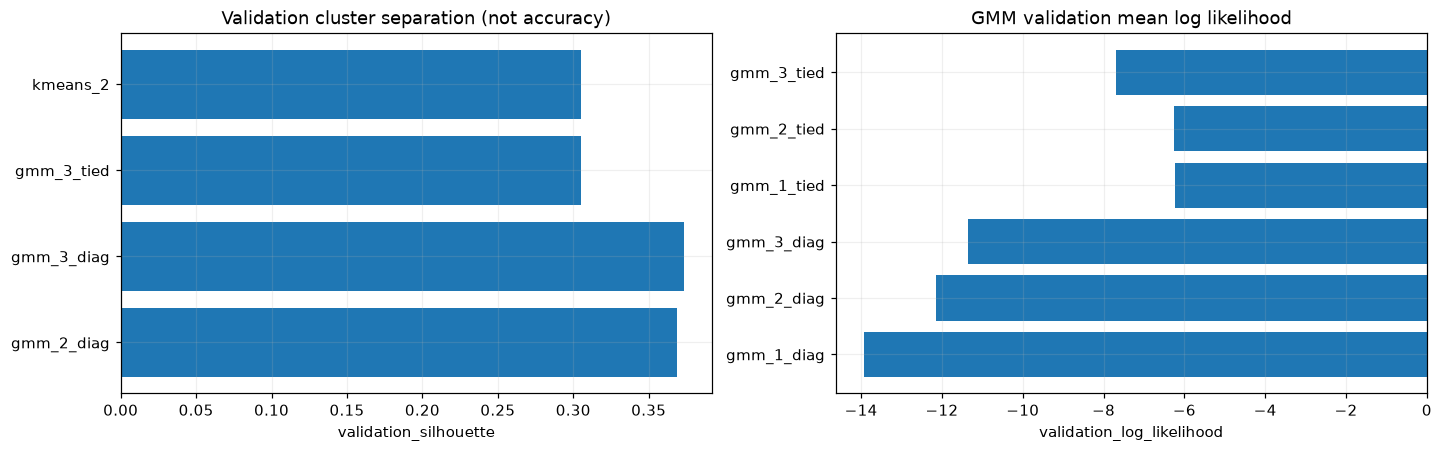

In [8]:
successful = unsupervised_metrics[unsupervised_metrics.status == 'ok']
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for ax, metric, title in zip(axes,
    ['validation_silhouette', 'validation_log_likelihood'],
    ['Validation cluster separation (not accuracy)', 'GMM validation mean log likelihood']):
    if metric in successful:
        values = successful.dropna(subset=[metric])
        ax.barh(values.model, values[metric])
    ax.set(title=title, xlabel=metric)
plt.show()


## Inspect one pipeline without changing the comparison

Choose a candidate explicitly below. Plot only training/validation assignments;
final test remains locked. Colors are arbitrary state IDs, not occupancy counts.
Density is a model score and membership is component affinity, not human presence confidence.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['amplitude_mean','amplitude_std_median','amplitude_mad_median',..., 'normalized_step_median','subcarrier_abs_correlation', 'pca1_variance_fraction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 wh

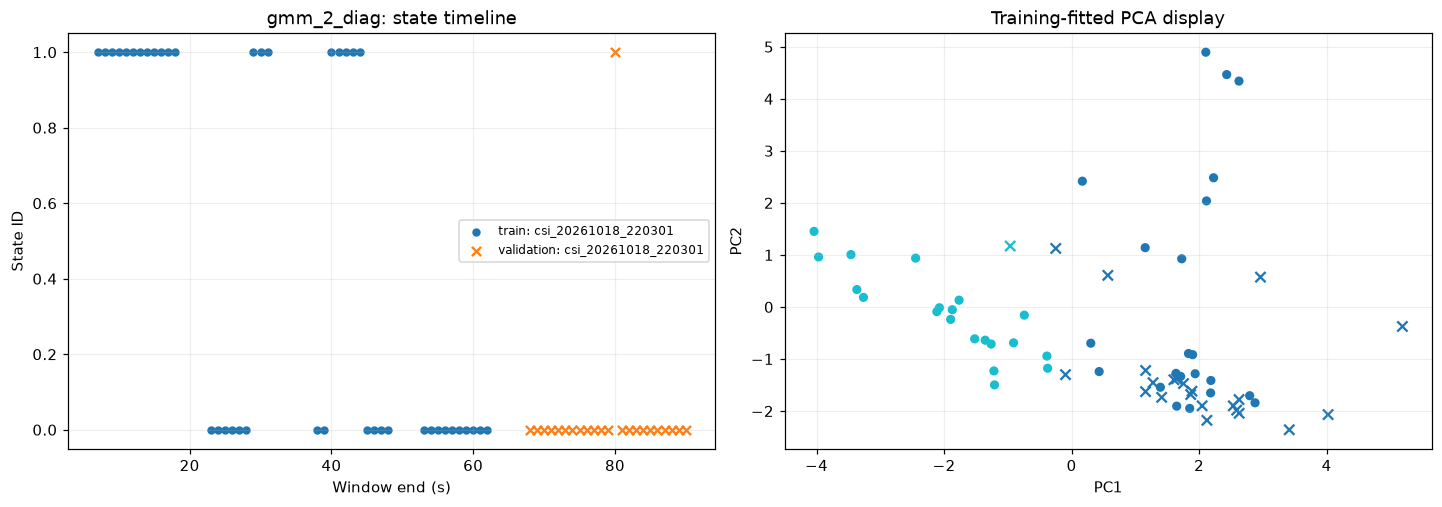

Training state feature profiles:


,amplitude_mean,amplitude_std_median,amplitude_mad_median,amplitude_cv_median,amplitude_step_median,amplitude_change_rate_median,normalized_std_median,normalized_step_median,subcarrier_abs_correlation,pca1_variance_fraction
state,,,,,,,,,,
0,19.752867,3.026503,1.260875,0.150645,1.542829,115.742965,0.019763,0.018732,0.258897,0.245030
1,18.605073,3.830205,2.382742,0.197382,2.852838,207.536079,0.020304,0.019882,0.241353,0.216922


Independent count annotations by state (if present):


person_count
state


Activity by state (if annotated):


activity,
state,
0,22
1,1


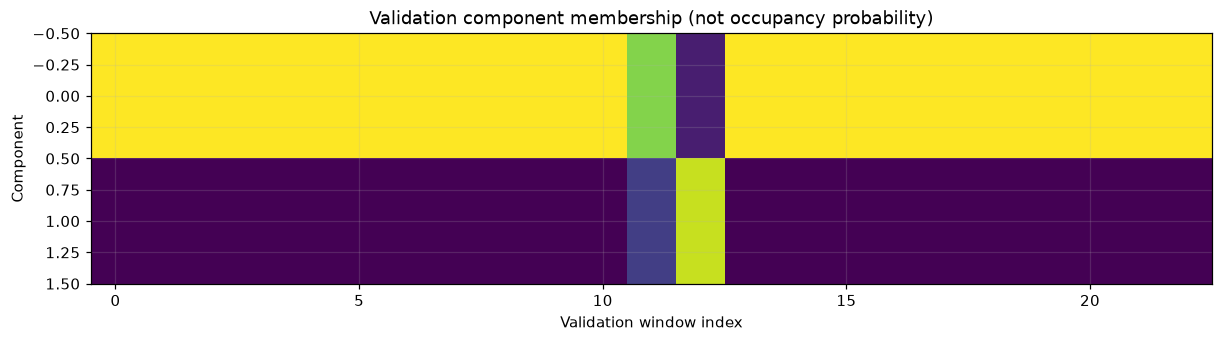

In [9]:
INSPECT_MODEL = 'gmm_2_diag'
result = unsupervised_results.get(INSPECT_MODEL)
if result is not None:
    display(result['pipeline'])
    train_labels = result['train_labels']
    rows = result['train_rows'].copy()
    rows['state'] = train_labels
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
    for session, group in rows.groupby('session_id'):
        axes[0].scatter(group.window_end_s, group.state, s=20, label=f'train: {session}')
    val = result['validation_rows'].copy()
    if 'validation_labels' in result:
        val['state'] = result['validation_labels']
        for session, group in val.groupby('session_id'):
            axes[0].scatter(group.window_end_s, group.state, marker='x', label=f'validation: {session}')
    axes[0].set(title=f'{INSPECT_MODEL}: state timeline', xlabel='Window end (s)', ylabel='State ID')
    axes[0].legend(fontsize=8)
    if 'train_projection' in result:
        xy = result['train_projection']
        axes[1].scatter(xy[:, 0], xy[:, 1], c=train_labels, cmap='tab10', s=25)
        if 'validation_labels' in result:
            xy = result['validation_projection']
            axes[1].scatter(xy[:, 0], xy[:, 1], c=result['validation_labels'], cmap='tab10',
                            vmin=min(train_labels), vmax=max(train_labels) if max(train_labels)>min(train_labels) else min(train_labels)+1,
                            marker='x', s=45)
    axes[1].set(title='Training-fitted PCA display', xlabel='PC1', ylabel='PC2')
    plt.show()
    print('Training state feature profiles:')
    display(rows.groupby('state')[FEATURE_COLUMNS].median())
    if len(val) and 'state' in val:
        print('Independent count annotations by state (if present):')
        display(pd.crosstab(val.state, val.person_count))
        print('Activity by state (if annotated):')
        display(pd.crosstab(val.state, val.activity))
        val.to_csv(REPORT_DIR/f'{INSPECT_MODEL}_validation_states.csv', index=False)
    if 'validation_membership' in result:
        membership = result['validation_membership']
        fig, ax = plt.subplots(figsize=(11, 3), layout='constrained')
        ax.imshow(membership.T, aspect='auto', vmin=0, vmax=1, cmap='viridis')
        ax.set(title='Validation component membership (not occupancy probability)',
               xlabel='Validation window index', ylabel='Component')
        plt.show()
else:
    print('No fitted result for INSPECT_MODEL. Check skipped/error rows above.')


## Save frozen pipelines and optionally evaluate the final test

Edit the selected name after development comparisons. Keep final-test evaluation
off until configuration is frozen. Inspecting repeated final-test results for
model selection invalidates its status as a held-out test. Joblib files are
trusted-local Python artifacts; load only your own trusted model files.


In [10]:
SELECTED_UNSUPERVISED_MODEL = INSPECT_MODEL
SELECTED_CHANGE_MODEL = 'ledoit_wolf'
RUN_FINAL_TEST = False

provenance = dict(split_mode=split_mode, fast_parameters=FAST_PARAMETERS,
    slow_parameters=SLOW_PARAMETERS, training_sessions=train.session_id.unique().tolist(),
    validation_sessions=validation.session_id.unique().tolist(),
    manifest=MANIFEST_PATH.read_text(encoding='utf-8'),
    labels=LABELS_PATH.read_text(encoding='utf-8'),
    purpose='signal states, not calibrated occupancy counts')
if SAVE_MODELS and SELECTED_UNSUPERVISED_MODEL in unsupervised_results:
    fitted = unsupervised_results[SELECTED_UNSUPERVISED_MODEL]['pipeline']
    save_bundle(MODEL_DIR/f'{SELECTED_UNSUPERVISED_MODEL}.joblib',
                fitted, FEATURE_COLUMNS, provenance)
    print('Saved selected unsupervised pipeline and feature schema.')
if SAVE_MODELS and SELECTED_CHANGE_MODEL in change_results:
    change = change_results[SELECTED_CHANGE_MODEL]
    save_bundle(MODEL_DIR/f'{SELECTED_CHANGE_MODEL}_change.joblib', change['pipeline'],
        FEATURE_COLUMNS, provenance, center=change['center'], scale=change['scale'],
        threshold=change['threshold'], cusum_parameters=change['cusum_parameters'])
if RUN_FINAL_TEST and len(final_test) and SELECTED_UNSUPERVISED_MODEL in unsupervised_results:
    pipe = unsupervised_results[SELECTED_UNSUPERVISED_MODEL]['pipeline']
    if hasattr(pipe, 'predict'):
        frozen = dict(pipeline=pipe, features=FEATURE_COLUMNS)
        output = final_test.copy()
        output['predicted_state'] = predict_bundle(frozen, final_test)
        output.to_csv(REPORT_DIR/'final_test_states.csv', index=False)
        print('Final test assignments saved; no fitting was performed.')
        good = quality_mask(output, FEATURE_COLUMNS)
        if good.any():
            z = pipe[:-1].transform(select_features(output.loc[good], FEATURE_COLUMNS))
            estimator = pipe.steps[-1][1]
            test_metrics = dict(model=SELECTED_UNSUPERVISED_MODEL,
                                quality_coverage=float(good.mean()), test_rows=int(good.sum()))
            if hasattr(estimator, 'score_samples'):
                test_metrics['mean_log_likelihood'] = float(np.mean(estimator.score_samples(z)))
            display(pd.DataFrame([test_metrics]))
            pd.DataFrame([test_metrics]).to_csv(REPORT_DIR/'final_test_state_metrics.csv', index=False)
if RUN_FINAL_TEST and len(final_test) and SELECTED_CHANGE_MODEL in change_results:
    from csi_models import frozen_change_trace, match_events
    frozen = change_results[SELECTED_CHANGE_MODEL]
    trace = frozen_change_trace(frozen, final_test, FEATURE_COLUMNS)
    trace.to_csv(REPORT_DIR/'final_test_changes.csv', index=False)
    display(pd.DataFrame([match_events(trace, events, EVENT_MATCH_TOLERANCE_SECONDS)]))
if not RUN_FINAL_TEST:
    print('Final test locked. No model fitting, scoring, or selection on test windows.')


Saved selected unsupervised pipeline and feature schema.


Final test locked. No model fitting, scoring, or selection on test windows.
